CRIAÇÃO DA BASE DE DADOS

In [13]:
'''Vou criar um neoronio de previsão de seguros'''
import numpy as np

import matplotlib.pyplot as plt

'''Esse seed serve para fixar o mesmo sorteio'''
np.random.seed(42)

'''criação de dados fake, aonde a mais jovel tera 15 e a mais velha tera 70 e serão 40 pessoas(size)'''

idades = np.random.randint(low=15, high= 70, size=40)

print(idades)

[53 66 43 29 57 22 35 53 33 37 25 25 38 67 50 54 38 17 36 67 16 38 58 44
 52 16 35 47 26 36 58 39 63 41 56 42 30 29 61 65]


In [14]:
'''Criação do vetor'''
labels = []

'''Laço que guarda usando apeend 0 para NÃO se a idade for menor do que 30 e 1 para SIM se a idade for maior do que 30'''
for idade in idades:
    if idade < 30:
        labels.append(0)

    else:
        labels.append(1)

'''Isso serve para embaralhar(por exemplo algumas pessoas de 40 nao tem seguro mais)'''
for i in range(0, 3):
    r = np.random.randint(0, len(labels) - 1)
    if labels[r] == 0:
        labels[r] = 1
    else:
        labels[r] = 0

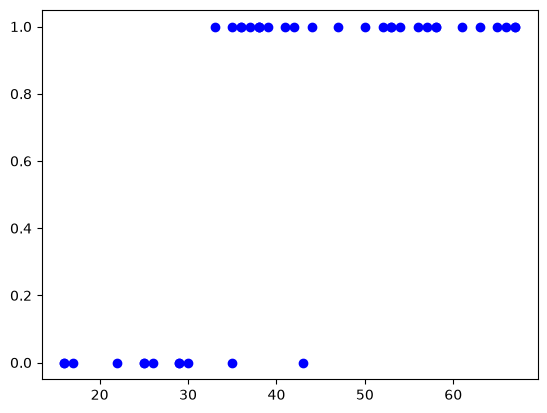

In [15]:

plt.scatter(idades, labels, color="blue")
plt.show()

PREDIÇÃO USANDO REGRESSAO LINEAR

In [16]:
'''Vamos fazer regressão linear'''

from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(idades.reshape(-1, 1), labels)

'''A regressao linear traça uma reta, aonde melhor traça os pontos dos dados e que melhor aproxima eles'''

'''Equação da reta: y = M * x + b'''

m = modelo.coef_[0]
b = modelo.intercept_

ENTENDENDO OS COEFICIENTES DAS RETAS

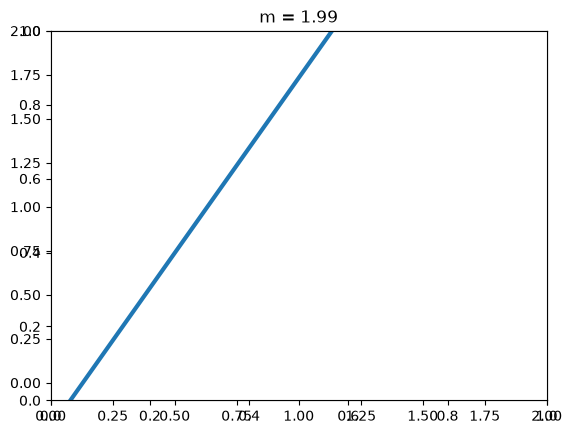

In [17]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


fig, ax = plt.subplots()

#Traçando o eixo x-axis e o eixo y-axis
'''Isso é uma limitação nos eixos para que o Zoom nao fique muito perto nem muito longe'''
axis = plt.axes(xlim = (0,2), ylim= (-0.1, 2))

#inicialização da variavel de linha

line, = axis.plot([], [], lw = 3)

#dados em que a linha irá
#contém(x, y)

def init():
    line.set_data([],[])
    return line,

def animate(i):
    m_copia = i * 0.01
    plt.title('m = ' + str(m_copia)) 
    x = np.arange(0.0, 10.0, 0.1)   
    y = m_copia * x + b                         
    line.set_data(x, y)
    return line,

ani = FuncAnimation(fig, animate, init_func= init, frames= 200, interval= 20, blit= True)

ani.save('m.gif', writer='pillow', fps=30)

REGRESSAO LINEAR DAQUELE CONJUNTO DE DADOS

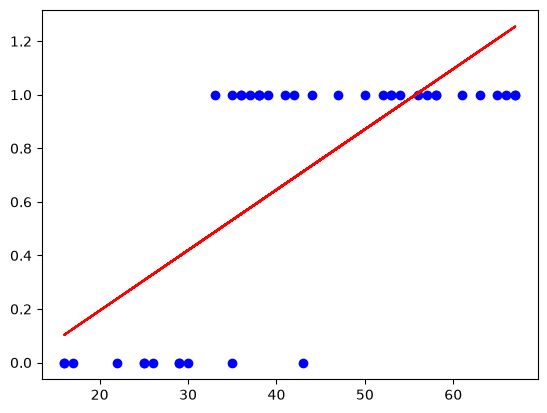

In [18]:
plt.plot(idades, idades * m + b, color='red')
plt.scatter(idades, labels, color='blue')
plt.show()